# Planning an experiment: how many runs, and which ones

The questions people actually bring to a design of experiments are practical. How many runs do I
need? How many replicates, and why? The full design is far too big, so what do I cut first, and what
next? I already have some runs, so can I use them, and what should I add?

This notebook answers those in six steps, in the order you would take them. Each step does the
calculation and then gives **a taste of the theory**: the one idea that makes the step work, so you
can adapt it to your own problem instead of following a recipe.

| Step | The question | The short answer |
|---|---|---|
| 1 | What am I measuring, and how noisy is it? | Pick the smallest effect worth detecting, $\Delta$. Estimate the noise $\sigma$ from true replicates, and plan with an upper bound on it. |
| 2 | How many runs, and how many replicates? | About $31(\sigma/\Delta)^2$ runs *in total* for 80% power. In a factorial every run informs every effect, so many factors need few or no replicates. |
| 3 | What do I cut first, then second, then third? | Two levels plus center points; then replicate only the center; then a fraction, which costs power and aliasing. |
| 4 | In what order do I run them? | Randomize the order, and block anything you cannot keep constant. |
| 5 | Can I use the runs I already have? | Code them and check what they can estimate: the rank of the model matrix. |
| 6 | What runs do I add? | The ones that most sharpen the model you want (D-optimal augmentation), with a block term for the new batch. |

Two companion notebooks go deeper. `factorial_designs.ipynb` is the full treatment of effects,
interactions, fractions, aliasing and center points behind steps 2, 3 and 6. `space_filling_designs.ipynb`
is for **computer experiments**, where a simulation replaces the lab; skip it for physical experiments.

The example is the same synthetic reactor as `factorial_designs.ipynb`: five factors, a table of
runs generated from a true model that the package states, so at the end you can check every plan
against the truth.

## Setup: where the package lives

This notebook does each calculation by hand and then checks it against `orteach`, the package in
`src/`. Run from a clone of the repository, `../../src` is right there. On Colab there is no clone
until this cell makes one, and no `gurobipy` until it installs it. Nothing here needs a secret.

In [1]:
import os, subprocess, sys

REPO_URL = "https://github.com/sear-labs/teaching-code"
REF = "v1.0.1"                               # the release this notebook ships in: Colab clones THIS

try:
    import google.colab                      # noqa: F401 - succeeds only on Colab
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

if ON_COLAB:
    if not os.path.isdir("/content/teaching-code"):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "--branch", REF, REPO_URL, "/content/teaching-code"], check=True)
    os.chdir("/content/teaching-code/notebooks/15_design_of_experiments")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "gurobipy>=11,<14"], check=True)

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "src")))
try:
    import orteach                            # noqa: F401
except ImportError:
    raise SystemExit("orteach not found: run this notebook from its own folder inside the repository, "
                     "so that ../../src exists.")
root = os.path.abspath(os.path.join("..", ".."))
print("package:", os.path.relpath(os.path.dirname(orteach.__file__), root))

package: src\orteach


## The runs, and the planning choices

The reactor has five factors, coded $-1$ for low and $+1$ for high: A temperature, B catalyst,
C time, D stirring, E feed rate. The table holds all 32 corner runs in **standard order** (A
alternates fastest) plus four runs at the **center**, every factor at its middle setting.

Three numbers are choices, not statistics, and they come first because everything below depends on
them. They sit in one cell so you can change them and re-run the notebook.

- `DELTA`: the smallest change in yield worth detecting. It comes from the science or the economics:
  what difference would change a decision?
- `ALPHA`: the false-alarm rate you accept, conventionally 5%.
- `TARGET`: the **power** you want, the chance of detecting an effect of size `DELTA` if it is
  there, conventionally 80%.

In [2]:
import itertools, math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from orteach import doe
from orteach.tolerance import AGREEMENT_RTOL, rel_diff

DELTA = 2.0          # smallest effect on yield worth detecting, in yield points
ALPHA = 0.05         # false-alarm rate of each test
TARGET = 0.80        # power wanted at DELTA
PLAN_CONF = 0.80     # plan with a sigma the true noise exceeds only 20% of the time

runs = doe.load_reactor()
corner = np.array(runs["kind"]) == "factorial"
X = np.column_stack([np.array(runs[f])[corner] for f in "ABCDE"]).astype(float)
y = np.array(runs["yield"])[corner]
y_center = np.array(runs["yield"])[~corner]
run_order = np.array(runs["run_order"])[corner]
print(f"{len(y)} corner runs, {len(y_center)} center runs; factors {doe.FACTOR_NAMES}")
print(f"planning for an effect of {DELTA} yield points, alpha {ALPHA}, power {TARGET}")

32 corner runs, 4 center runs; factors {'A': 'temperature', 'B': 'catalyst', 'C': 'time', 'D': 'stirring', 'E': 'feed rate'}
planning for an effect of 2.0 yield points, alpha 0.05, power 0.8


---

## Step 1: what you measure, and how noisy it is

You cannot size an experiment without two numbers: the effect you want to see, $\Delta$, and the
run-to-run noise, $\sigma$. The first is your choice. The second has to be measured.

**What counts as a replicate.** A replicate is the *whole* run done again: fresh setup, fresh
material, same settings. Measuring the same sample twice, or reading the same unit at many time
points, is a **repeated measurement**. It tells you about the measuring, not about the run-to-run
variation that decides whether an effect is real. Counting repeated measurements as replicates is
the most common way a study ends up claiming more certainty than it has.

The reactor's four center runs are true replicates: the same settings, run four separate times.
Their spread is the **pure error**, an estimate of $\sigma$ that needs no model.

### A taste of theory: an estimate of noise is itself noisy

If the runs are Normal, $(n-1)s^2/\sigma^2$ follows a chi-square distribution with $n-1$ degrees of
freedom. Inverting that gives an interval for $\sigma$:
$$
s\sqrt{\frac{n-1}{\chi^2_{1-a/2,\;n-1}}} \;\le\; \sigma \;\le\; s\sqrt{\frac{n-1}{\chi^2_{a/2,\;n-1}}}.
$$
With only a few replicates, that interval is wide. Planning with $s$ itself is optimistic half the
time, so plan with an **upper bound** instead: one the true $\sigma$ exceeds only rarely.

Predict before you run it: from four replicates, how wide do you expect the 95% interval for
$\sigma$ to be, as a multiple of $s$?

In [3]:
n_c = len(y_center)
df_pure = n_c - 1
s = y_center.std(ddof=1)
sig_lo = s * np.sqrt(df_pure / stats.chi2.ppf(0.975, df_pure))
sig_hi = s * np.sqrt(df_pure / stats.chi2.ppf(0.025, df_pure))
sigma_plan = s * np.sqrt(df_pure / stats.chi2.ppf(1 - PLAN_CONF, df_pure))
print("center runs:", y_center.tolist())
print(f"s = {s:.3f} on {df_pure} degrees of freedom")
print(f"95% interval for sigma: {sig_lo:.3f} to {sig_hi:.3f}  (from {sig_lo / s:.2f} s to {sig_hi / s:.2f} s)")
print(f"planning value, the {PLAN_CONF:.0%} upper bound: sigma_plan = {sigma_plan:.3f}")

center runs: [60.72, 61.72, 59.66, 59.3]
s = 1.094 on 3 degrees of freedom
95% interval for sigma: 0.620 to 4.080  (from 0.57 s to 3.73 s)
planning value, the 80% upper bound: sigma_plan = 1.890


The upper end of that interval is several times $s$. How many replicates does it take before the
interval is tight? The bounds depend only on $n$, so they can be drawn once for every experiment.

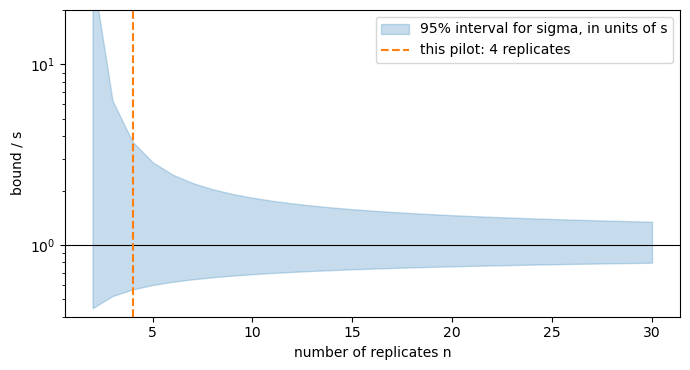

Figure: the 95% interval for sigma as a multiple of s, against the number of replicates, on a log scale. With 4 replicates it runs from 0.57 s to 3.73 s; with 10, from 0.69 s to 1.83 s; with 30, from 0.80 s to 1.34 s.


In [4]:
ns = np.arange(2, 31)
hi_ratio = np.sqrt((ns - 1) / stats.chi2.ppf(0.025, ns - 1))
lo_ratio = np.sqrt((ns - 1) / stats.chi2.ppf(0.975, ns - 1))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.fill_between(ns, lo_ratio, hi_ratio, color="tab:blue", alpha=0.25, label="95% interval for sigma, in units of s")
ax.axhline(1, color="black", lw=0.8)
ax.axvline(n_c, color="tab:orange", ls="--", label=f"this pilot: {n_c} replicates")
ax.set_yscale("log"); ax.set_ylim(0.4, 20); ax.set_xlabel("number of replicates n"); ax.set_ylabel("bound / s")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Figure: the 95% interval for sigma as a multiple of s, against the number of replicates, on a log "
      f"scale. With {n_c} replicates it runs from {lo_ratio[n_c - 2]:.2f} s to {hi_ratio[n_c - 2]:.2f} s; with "
      f"10, from {lo_ratio[8]:.2f} s to {hi_ratio[8]:.2f} s; with 30, from {lo_ratio[28]:.2f} s to {hi_ratio[28]:.2f} s.")

The band narrows fast up to about ten replicates and slowly after. That is a reason to put real
effort into the pilot, or to find an earlier study's replicates: a better $\sigma$ can change the
size of the whole experiment.

---

## Step 2: how many runs, and how many replicates

### A taste of theory: where the formula comes from

An effect is a difference of two means. In a two-level design with $N$ runs, half are at the high
setting and half at the low, so
$$
\operatorname{Var}(\hat{e}) = \frac{\sigma^2}{N/2} + \frac{\sigma^2}{N/2} = \frac{4\sigma^2}{N},
\qquad \operatorname{SE}(\hat{e}) = \frac{2\sigma}{\sqrt{N}}.
$$
A test declares the effect real when $|\hat{e}|/\operatorname{SE}$ exceeds $z_{\alpha/2}$, which is 1.96
for 5%. If the true effect is $\Delta$, the statistic is centred at $\lambda = \Delta/\operatorname{SE}$, and
it clears the bar with probability about $\Phi(\lambda - z_{\alpha/2})$. Setting that equal to the
target power and solving for $N$:
$$
N = 4\,(z_{\alpha/2} + z_{\beta})^2 \left(\frac{\sigma}{\Delta}\right)^2 \approx 31\left(\frac{\sigma}{\Delta}\right)^2
\quad \text{for } \alpha = 0.05 \text{ and } 80\% \text{ power}.
$$

**$N$ is the total number of runs, not runs per combination.** Every run sits on one side of every
effect, so all $N$ runs inform every main effect at once. This is called **hidden replication**, and
it is the reason "how many replicates?" has no answer until you know how many factors there are.

Predict before you run it: with five factors, how many replicates of the $2^5$ will you need?

In [5]:
z_a, z_b = stats.norm.ppf(1 - ALPHA / 2), stats.norm.ppf(TARGET)
N_needed = 4 * (z_a + z_b) ** 2 * (sigma_plan / DELTA) ** 2
print(f"z_alpha/2 = {z_a:.3f}, z_beta = {z_b:.3f}; constant 4(z+z)^2 = {4 * (z_a + z_b) ** 2:.2f}")
print(f"runs needed in total: N = {N_needed:.1f}\n")
print(f"{'factors k':>9} {'2^k':>5} {'replicates':>11} {'total runs':>11}")
for k in range(2, 7):
    r = math.ceil(N_needed / 2 ** k)
    print(f"{k:9d} {2 ** k:5d} {r:11d} {r * 2 ** k:11d}")

z_alpha/2 = 1.960, z_beta = 0.842; constant 4(z+z)^2 = 31.40
runs needed in total: N = 28.1

factors k   2^k  replicates  total runs
        2     4           8          32
        3     8           4          32
        4    16           2          32
        5    32           1          32
        6    64           1          64


The same power needs eight copies of a two-factor design and a single copy of a five-factor one.
The five-factor experiment is not cheating: each of its 32 runs is doing duty for every factor at
once. With six factors, even one copy is twice what the power calculation asks for, which is where
fractions (step 3) come in.

### Power against the number of runs

The formula also runs the other way: for a given $N$, what power do you get? Here it is for three
sizes of effect relative to the noise.

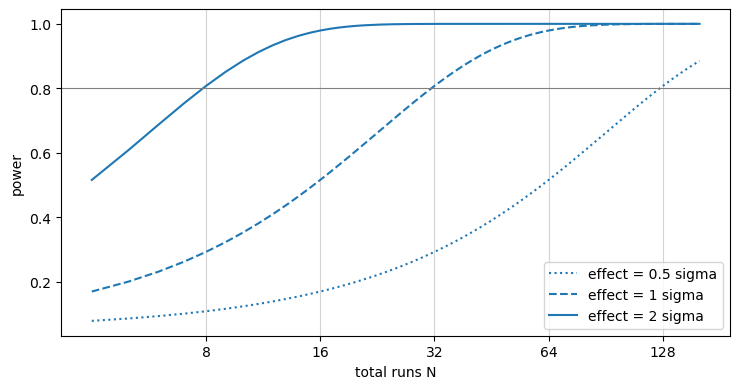

Figure: power against total runs (log scale) for effects of 0.5, 1 and 2 sigma, with a gray line at 80%. The 2-sigma curve reaches it at 8 runs, the 1-sigma curve at 32, the 0.5-sigma curve at 126. Halving the effect quadruples the runs.


In [6]:
Ns = np.arange(4, 161)
fig, ax = plt.subplots(figsize=(7.5, 4))
crossings = {}
for ratio, style in ((0.5, ":"), (1.0, "--"), (2.0, "-")):
    lam = ratio * np.sqrt(Ns) / 2
    pw = stats.norm.sf(z_a - lam) + stats.norm.cdf(-z_a - lam)
    crossings[ratio] = int(Ns[np.argmax(pw >= TARGET)]) if (pw >= TARGET).any() else None
    ax.plot(Ns, pw, style, color="tab:blue", label=f"effect = {ratio:g} sigma")
ax.axhline(TARGET, color="gray", lw=0.8)
for n2 in (8, 16, 32, 64, 128):
    ax.axvline(n2, color="lightgray", lw=0.8, zorder=0)
ax.set_xscale("log", base=2); ax.set_xticks([8, 16, 32, 64, 128], ["8", "16", "32", "64", "128"])
ax.set_xlabel("total runs N"); ax.set_ylabel("power"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
print(f"Figure: power against total runs (log scale) for effects of 0.5, 1 and 2 sigma, with a gray line at "
      f"{TARGET:.0%}. The 2-sigma curve reaches it at {crossings[2.0]} runs, the 1-sigma curve at "
      f"{crossings[1.0]}, the 0.5-sigma curve at {crossings[0.5]}. Halving the effect quadruples the runs.")

### Checking the formula: exact power, then a simulation

The formula uses a Normal approximation and pretends $\sigma$ is known. In the analysis, $\sigma$ is
estimated from the residuals, so the test is a $t$ test with the **residual degrees of freedom**:
runs minus the number of terms fitted. Its statistic follows a *noncentral* $t$ distribution with
noncentrality $\lambda$, which gives the exact power.

Take the design step 3 will arrive at: the 32 corners plus the four center runs, fitting an
intercept, five main effects, ten two-factor interactions and a curvature term. That is 17 terms on
36 runs, leaving 19 degrees of freedom.

Then simulate it. Build the experiment thousands of times with a true A effect of exactly `DELTA`
and noise `sigma_plan`, analyse each one, and count how often A is declared real. Predict whether the
simulated rate will land above or below the 80% target.

In [7]:
D36 = np.vstack([X, np.zeros((n_c, 5))])
words2 = ["".join(c) for r in (1, 2) for c in itertools.combinations("ABCDE", r)]
M36 = np.column_stack([np.ones(36)] + [np.prod(D36[:, ["ABCDE".index(ch) for ch in w]], axis=1) for w in words2]
                      + [np.r_[np.zeros(32), np.ones(n_c)]])                 # last column: curvature
df36 = M36.shape[0] - M36.shape[1]
se36 = 2 * sigma_plan / np.sqrt(32)
tc36 = stats.t.ppf(1 - ALPHA / 2, df36)
power36 = stats.nct.sf(tc36, df36, DELTA / se36) + stats.nct.cdf(-tc36, df36, DELTA / se36)
print(f"{M36.shape[1]} terms on {M36.shape[0]} runs: {df36} residual degrees of freedom")
print(f"SE of an effect {se36:.3f}; noncentrality {DELTA / se36:.3f}; exact power {power36:.3f}")

SEED, REPS = 515, 4000
rng = np.random.default_rng(SEED)
print(f"simulating {REPS} experiments, seed {SEED}")
Y = (DELTA / 2) * D36[:, [0]] + rng.normal(0, sigma_plan, (36, REPS))   # true A coefficient DELTA/2
B = np.linalg.solve(M36.T @ M36, M36.T @ Y)
s2 = ((Y - M36 @ B) ** 2).sum(axis=0) / df36
t_A = B[1] / np.sqrt(s2 * np.linalg.inv(M36.T @ M36)[1, 1])
sim_power = (np.abs(t_A) > tc36).mean()
mc_se = np.sqrt(sim_power * (1 - sim_power) / REPS)
print(f"declared real in {sim_power:.3f} of them (Monte Carlo SE {mc_se:.3f}); exact {power36:.3f}")
assert abs(sim_power - power36) < 4 * mc_se, "the simulation disagrees with the noncentral t power"

17 terms on 36 runs: 19 residual degrees of freedom
SE of an effect 0.668; noncentrality 2.992; exact power 0.810
simulating 4000 experiments, seed 515
declared real in 0.809 of them (Monte Carlo SE 0.006); exact 0.810


The simulation lands within its own sampling error of the exact power, and both are close to the
target, because 32 corner runs is the first $2^k$ above the $N$ the formula asked for.

---

## Step 3: the reduction ladder

Suppose the first plan on the table is the one many studies start from: every factor at three
levels, every combination, three replicates each. For five factors that is $3^5 \times 3 = 729$ runs.
Each rung below cuts it, and each says what it gives up.

**Rung 1: two levels plus center points.** Three levels are there to detect curvature. But a third
of a three-level design sits at the middle setting, where the coded value is 0, and a run at 0
contributes nothing to a linear effect: in the theory of step 2, the variance of an effect is
$4\sigma^2 / \sum x_i^2$ and a middle run adds 0 to that sum. Put the runs at the extremes, where
they sharpen every effect, and spend a handful at the center to *test* for curvature instead of
modelling it. What you give up: if the test finds curvature, it cannot say which factor is curved.
That takes more runs later (step 6).

**Rung 2: replicate only the center.** Step 2 showed that hidden replication already gives the
corners their power. The reason to replicate at all is to estimate $\sigma$ without a model, and
replicated center runs do that without disturbing the balance of the corners. What you give up:
nothing, if step 2's arithmetic says the unreplicated corners are enough.

**Rung 3: a half fraction.** Run 16 of the 32 corners, chosen so that every main effect and
two-factor interaction can still be estimated (resolution V, built in `factorial_designs.ipynb`).
What you give up: half the runs, so the standard error grows by $\sqrt{2}$, and three-factor
interactions now hide behind two-factor ones. Fitting 17 terms to 20 runs also leaves only three
degrees of freedom for error, which makes the $t$ test timid; more center points buy them back
cheaply.

**Rung 4: a quarter fraction, for screening only.** Eight corners. Main effects are now aliased
with two-factor interactions, so this design can only say which factors deserve a closer look.

Predict before you run it: which rung is the first to drop below 80% power for a 2-point effect?

In [8]:
# name, corner runs, center runs, sum of x^2 in one factor's column, terms fitted
ladder = [("3^5, 3 replicates", 0, 0, 729 * 2 / 3, 21),
          ("2^5 x 3 + 4 center", 96, 4, 96, 17),
          ("2^5 + 4 center", 32, 4, 32, 17),
          ("half + 4 center", 16, 4, 16, 17),
          ("half + 8 center", 16, 8, 16, 17),
          ("quarter + 4 center", 8, 4, 8, 7)]
print(f"{'design':20} {'runs':>5} {'SE':>6} {'df':>4} {'power @ DELTA':>14} {'power @ 2 DELTA':>16}")
ladder_rows = []
for name, nf, nc, sx2, p in ladder:
    n_runs = 729 if nf == 0 else nf + nc
    se, df = 2 * sigma_plan / np.sqrt(sx2), n_runs - p
    tc = stats.t.ppf(1 - ALPHA / 2, df)
    pw = []
    for d in (DELTA, 2 * DELTA):
        lower = stats.nct.cdf(-tc, df, d / se)      # nan when d/se is huge; the tail is then ~0
        pw.append(stats.nct.sf(tc, df, d / se) + np.nan_to_num(lower))
    ladder_rows.append((name, n_runs, se, df, pw[0], pw[1]))
    print(f"{name:20} {n_runs:5d} {se:6.3f} {df:4d} {pw[0]:14.3f} {pw[1]:16.3f}")

design                runs     SE   df  power @ DELTA  power @ 2 DELTA
3^5, 3 replicates      729  0.172  708          1.000            1.000
2^5 x 3 + 4 center     100  0.386   83          0.999            1.000
2^5 + 4 center          36  0.668   19          0.810            1.000
half + 4 center         20  0.945    3          0.315            0.796
half + 8 center         24  0.945    7          0.447            0.950
quarter + 4 center      12  1.337    5          0.231            0.670


The same ladder as a picture: bar length is the number of runs, on a log scale, and each bar is
labelled with its power for a 2-point effect.

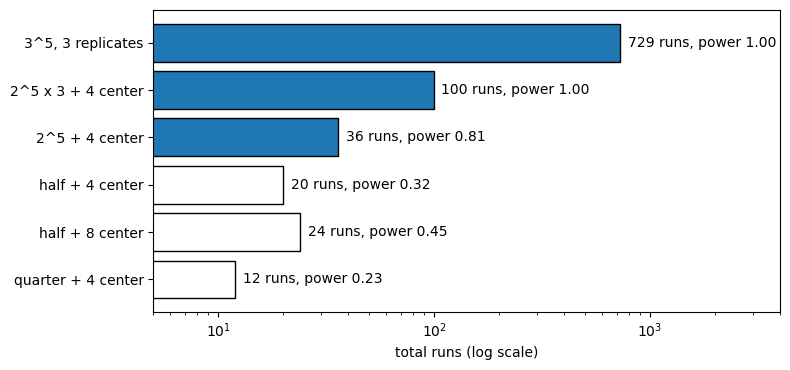

Figure: horizontal bars of total runs for six designs, log scale. Filled bars reach 80% power for a 2.0-point effect: 3^5, 3 replicates, 2^5 x 3 + 4 center, 2^5 + 4 center. The smallest of them is 2^5 + 4 center at 36 runs, against 729 for the starting plan. The open bars fall short.


In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = [r[0] for r in ladder_rows][::-1]
ax.barh(names, [r[1] for r in ladder_rows][::-1],
        color=["tab:blue" if r[4] >= TARGET else "white" for r in ladder_rows][::-1], edgecolor="black")
for i, r in enumerate(ladder_rows[::-1]):
    ax.text(r[1] * 1.08, i, f"{r[1]} runs, power {r[4]:.2f}", va="center")
ax.set_xscale("log"); ax.set_xlim(5, 4000); ax.set_xlabel("total runs (log scale)")
plt.tight_layout(); plt.show()
ok = [r for r in ladder_rows if r[4] >= TARGET]
print(f"Figure: horizontal bars of total runs for six designs, log scale. Filled bars reach {TARGET:.0%} power "
      f"for a {DELTA}-point effect: {', '.join(r[0] for r in ok)}. The smallest of them is "
      f"{min(ok, key=lambda r: r[1])[0]} at {min(r[1] for r in ok)} runs, against 729 for the starting plan. "
      f"The open bars fall short.")

**Reading the ladder.** The first two rungs are free: they cut 729 runs to 36 and keep the power.
The third is not free for a 2-point effect, and no number of extra center points fixes that,
because center points add degrees of freedom but no precision. A fraction is the right move when
the effects that matter are larger (look at the last column) or as a first stage you intend to
augment. The quarter fraction answers a different question, *which factors matter at all*, and
should not be used to estimate anything.

---

## Step 4: randomize the order, and block what you cannot hold constant

### A taste of theory: drift becomes a fake effect

Suppose the response creeps upward by a fixed amount with every run, from a warming room or an
ageing batch of material. Add a column for time to the design. A drift of $d$ per run adds $d$ times
time to every response, so it adds exactly $d$ times *the effect of the time column* to every
factor's effect. If a factor's column is correlated with time, the drift lands on it.

In standard order, E is low for the first sixteen runs and high for the last sixteen, so E is almost
perfectly correlated with time. Predict what a small drift does to E's effect when the runs are made
in standard order, and when they are made in the table's randomized order.

In [10]:
DRIFT = 0.1                                     # yield points per run
time_std = np.arange(1, 33)                     # made in standard order
time_rand = run_order                           # made in the table's random order
print(f"drift {DRIFT} per run.  bias = DRIFT x (effect of the time column)\n")
print(f"{'':12} {'standard order':>15} {'random order':>14}")
bias_std, bias_rand = {}, {}
for j, f in enumerate("ABCDE"):
    hi, lo = X[:, j] > 0, X[:, j] < 0
    eff_y = y[hi].mean() - y[lo].mean()
    bias_std[f] = ((y + DRIFT * time_std)[hi].mean() - (y + DRIFT * time_std)[lo].mean()) - eff_y
    bias_rand[f] = ((y + DRIFT * time_rand)[hi].mean() - (y + DRIFT * time_rand)[lo].mean()) - eff_y
    print(f"{f} {doe.FACTOR_NAMES[f]:10} {bias_std[f]:+15.2f} {bias_rand[f]:+14.2f}")

drift 0.1 per run.  bias = DRIFT x (effect of the time column)

              standard order   random order
A temperature           +0.10          -0.01
B catalyst             +0.20          +0.56
C time                 +0.40          +0.02
D stirring             +0.80          -0.77
E feed rate            +1.60          -0.13


Seen as bars:

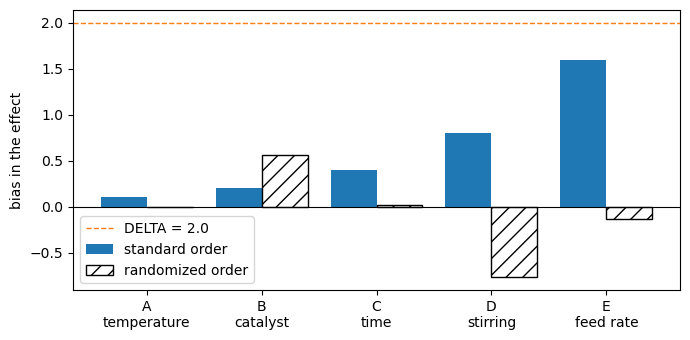

Figure: the bias a drift of 0.1 per run adds to each main effect. In standard order E picks up +1.60, close to the 2.0-point effect the study is sized to detect, and D +0.80; in the randomized order the largest bias is -0.77, on D. The dashed line marks DELTA.


In [11]:
xs = np.arange(5)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(xs - 0.2, [bias_std[f] for f in "ABCDE"], 0.4, label="standard order", color="tab:blue")
ax.bar(xs + 0.2, [bias_rand[f] for f in "ABCDE"], 0.4, label="randomized order", color="white", edgecolor="black", hatch="//")
ax.axhline(DELTA, color="tab:orange", ls="--", lw=1, label=f"DELTA = {DELTA}")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xs, [f"{f}\n{doe.FACTOR_NAMES[f]}" for f in "ABCDE"]); ax.set_ylabel("bias in the effect")
ax.legend(); plt.tight_layout(); plt.show()
worst_rand = max(bias_rand, key=lambda f: abs(bias_rand[f]))
print(f"Figure: the bias a drift of {DRIFT} per run adds to each main effect. In standard order E picks up "
      f"{bias_std['E']:+.2f}, close to the {DELTA}-point effect the study is sized to detect, and D "
      f"{bias_std['D']:+.2f}; in the randomized order the largest bias is {bias_rand[worst_rand]:+.2f}, on "
      f"{worst_rand}. The dashed line marks DELTA.")

In standard order the bias doubles from factor to factor, because each factor's column changes half
as often as the one before it, and it lands hardest on E every time the experiment is run this way.
Randomizing does not remove the drift. It breaks that systematic link: in a random order the bias
scatters, here -0.77 on D, and averaged over all possible orders it is zero. The drift then behaves
like extra noise, which the error estimate absorbs, instead of a fake effect built into the design.

**Blocking** handles a nuisance you *know* about. If the 32 runs must be split over two days, choose
which runs go on which day so that the day difference lands on an effect you were never going to
estimate. Assign day by the sign of the ABCDE column. Day is then orthogonal to every main effect and
every two-factor interaction, so a shift between days cannot touch them.

**Two cases need more than this, and are common in dissertation work.** If a factor is hard to
change (an oven temperature, a chamber setting), runs get grouped by it, and the analysis must treat
those groups as whole plots: a **split-plot** design. If each unit is measured repeatedly over time,
those measurements are not replicates (step 1) and the analysis needs a repeated-measures or
mixed model.

In [12]:
DAY_SHIFT = 2.0                                  # day two runs 2 points higher, for no reason in the design
day2 = X[:, 0] * X[:, 1] * X[:, 2] * X[:, 3] * X[:, 4] > 0
y_days = y + DAY_SHIFT * day2
change = {}
for w in words2 + ["ABCDE"]:
    col = np.prod(X[:, ["ABCDE".index(ch) for ch in w]], axis=1)
    change[w] = (y_days[col > 0].mean() - y_days[col < 0].mean()) - (y[col > 0].mean() - y[col < 0].mean())
print(f"{day2.sum()} runs on day two; day shift {DAY_SHIFT}")
print(f"largest change in any main effect or two-factor interaction: {max(abs(change[w]) for w in words2):.1e}")
print(f"change in the ABCDE effect: {change['ABCDE']:+.2f}")

16 runs on day two; day shift 2.0
largest change in any main effect or two-factor interaction: 7.1e-15
change in the ABCDE effect: +2.00


---

## Step 5: use the runs you already have

A common starting point: someone has already run a few experiments, usually one factor at a time.
Here, a baseline with every factor low, then each factor raised on its own: six runs, all of them
corners of the $2^5$, so their yields are in the table.

### A taste of theory: what a set of runs can estimate

Write the model you want as a matrix $M$, one row per run and one column per term. The least-squares
coefficients are $\hat\beta = (M^\top M)^{-1} M^\top y$, and their variances are the diagonal of
$\sigma^2 (M^\top M)^{-1}$. Two facts follow.

- A set of runs can estimate a model **only if $M$ has full column rank**: as many independent
  columns as terms. Count the rank and you know what the runs can and cannot tell you.
- One-factor-at-a-time estimates each effect from two runs, so its variance is $2\sigma^2$. A
  factorial with $N$ runs gives $4\sigma^2/N$: with eight runs, a quarter of the variance, and it
  estimates interactions too.

Predict before you run it: how many of the 16 terms (intercept, 5 main effects, 10 interactions) can
these six runs estimate?

In [13]:
ofat = [0, 1, 2, 4, 8, 16]                      # standard-order rows: all low, then A, B, C, D, E alone
Xo, yo = X[ofat], y[ofat]
print(" A B C D E   yield")
for row, v in zip(Xo, yo):
    print(" " + " ".join("+" if s_ > 0 else "-" for s_ in row) + f"   {v:5.2f}")
M_main = np.column_stack([np.ones(6), Xo])
M_full = np.column_stack([np.ones(6)] + [np.prod(Xo[:, ["ABCDE".index(ch) for ch in w]], axis=1) for w in words2])
print(f"\nmain-effects model: {M_main.shape[1]} terms, rank {np.linalg.matrix_rank(M_main)}")
print(f"with interactions:  {M_full.shape[1]} terms, rank {np.linalg.matrix_rank(M_full)}")
var_ofat = 4 * np.diag(np.linalg.inv(M_main.T @ M_main))[1:]      # effect = 2 x coefficient
print(f"variance of each main effect, in units of sigma^2: {var_ofat.round(3).tolist()}")
print(f"a 2^(5-2) factorial with 8 runs: {4 / 8:.3f}")

 A B C D E   yield
 - - - - -   48.64
 + - - - -   57.75
 - + - - -   54.59
 - - + - -   47.25
 - - - + -   53.88
 - - - - +   50.02

main-effects model: 6 terms, rank 6
with interactions:  16 terms, rank 6
variance of each main effect, in units of sigma^2: [2.0, 2.0, 2.0, 2.0, 2.0]
a 2^(5-2) factorial with 8 runs: 0.500


Six runs, six independent columns: the main-effects model is **saturated**. Every run is spent
estimating a coefficient, none is left to estimate noise, and no interaction can be estimated at
all. Interactions are not ruled out by these runs. They are invisible to them.

---

## Step 6: choose the runs to add

### A taste of theory: the D-criterion

Among all the runs you could add, which are worth most? The joint confidence region for the
coefficients is an ellipsoid whose volume is proportional to $1/\sqrt{\det(M^\top M)}$. A design that
makes $\det(M^\top M)$ large makes that region small: it pins all the coefficients down at once.
That is **D-optimality**. Adding runs one at a time, each time taking the candidate that most
increases $\log\det(M^\top M)$, is the simplest way to augment a design, and it starts from whatever
runs you already have.

Two details matter in practice. While the existing runs cannot estimate every term, $\det(M^\top M)$
is zero; a tiny ridge, `doe.AUGMENT_RIDGE`, keeps the comparison meaningful, so the first runs added
are the ones that make new terms estimable. And the new runs are a new batch, made later, perhaps on
a different instrument, so the model gets a **block column**: $-1$ for the old runs and $+1$ for the
new ones, which soaks up a shift between batches before it reaches the effects.

The target model is the 16 terms of step 5 plus the block, 17 in all. The candidates are the 26
corners not yet run. Add 16, as many new runs as a fresh half fraction would cost. Predict: will
the first few runs added raise the rank or the determinant?

In [14]:
N_ADD = 16
cand_rows = [i for i in range(32) if i not in ofat]
candidates = X[cand_rows]
term_idx = [["ABCDE".index(ch) for ch in w] for w in words2]
rows, batch, chosen, rank_path, logdet_path = Xo.copy(), -np.ones(6), [], [], []
for step in range(N_ADD):
    best_i, best_v = None, -np.inf
    for i, cand in enumerate(candidates):
        if i in chosen:
            continue
        trial, tb = np.vstack([rows, cand]), np.append(batch, 1.0)
        M = np.column_stack([np.ones(len(trial))] + [np.prod(trial[:, ix], axis=1) for ix in term_idx] + [tb])
        v = np.linalg.slogdet(M.T @ M + doe.AUGMENT_RIDGE * np.eye(M.shape[1]))[1]
        if v > best_v:
            best_i, best_v = i, v
    chosen.append(best_i)
    rows, batch = np.vstack([rows, candidates[best_i]]), np.append(batch, 1.0)
    M = np.column_stack([np.ones(len(rows))] + [np.prod(rows[:, ix], axis=1) for ix in term_idx] + [batch])
    rank_path.append(int(np.linalg.matrix_rank(M))); logdet_path.append(best_v)
added = [cand_rows[i] for i in chosen]
print("added, as standard-order rows of the 2^5:", added)
print("rank after each addition:", rank_path)

added, as standard-order rows of the 2^5: [26, 19, 25, 28, 11, 21, 13, 7, 14, 22, 31, 5, 17, 3, 12, 18]
rank after each addition: [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 17, 17, 17, 17, 17]


The rank climbs by one with every early addition, then stops at 17, the number of terms; after that
each run adds precision instead of new terms. Both phases, drawn:

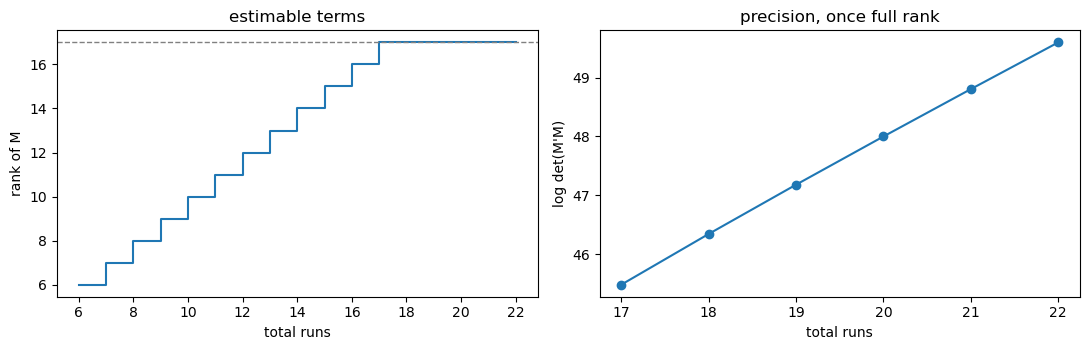

Figure: left, the rank of the 17-column model matrix as runs are added to the six existing ones; it reaches 17 at 17 runs, the dashed line. Right, from then on, log det(M'M) rises from 45.5 to 49.6 as the remaining runs sharpen the estimates.


In [15]:
full_at = rank_path.index(17) if 17 in rank_path else None
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
n_tot = 6 + np.arange(1, N_ADD + 1)
axes[0].step(np.r_[6, n_tot], [np.linalg.matrix_rank(M_full)] + rank_path, where="post", color="tab:blue"); axes[0].axhline(17, color="gray", ls="--", lw=1)
axes[0].set_xlabel("total runs"); axes[0].set_ylabel("rank of M"); axes[0].set_title("estimable terms")
full = n_tot[full_at:]
axes[1].plot(full, logdet_path[full_at:], "o-", color="tab:blue")
axes[1].set_xlabel("total runs"); axes[1].set_ylabel("log det(M'M)"); axes[1].set_title("precision, once full rank")
plt.tight_layout(); plt.show()
print(f"Figure: left, the rank of the 17-column model matrix as runs are added to the six existing ones; it "
      f"reaches 17 at {full[0]} runs, the dashed line. Right, from then on, log det(M'M) rises from "
      f"{logdet_path[full_at]:.1f} to {logdet_path[-1]:.1f} as the remaining runs sharpen the estimates.")

Now analyse the augmented design with the yields from the table, and compare it with what a fresh
half fraction would cost. Both spend 16 new runs. The half fraction throws away the six old runs and
fits 16 terms to 16 runs, leaving nothing to estimate error; the augmented design keeps them.

In [16]:
rows_aug = ofat + added
batch_aug = np.r_[-np.ones(6), np.ones(N_ADD)]
M_aug = np.column_stack([np.ones(len(rows_aug))] + [np.prod(X[rows_aug][:, ix], axis=1) for ix in term_idx] + [batch_aug])
XtX_inv = np.linalg.inv(M_aug.T @ M_aug)
beta_aug = XtX_inv @ M_aug.T @ y[rows_aug]
df_aug = len(rows_aug) - M_aug.shape[1]
s_aug = np.sqrt(((y[rows_aug] - M_aug @ beta_aug) ** 2).sum() / df_aug)
se_main = 2 * np.sqrt(np.diag(XtX_inv)[1:6])                 # effect SE in units of sigma
d_eff = np.exp(np.linalg.slogdet(M_aug.T @ M_aug)[1] / M_aug.shape[1]) / len(rows_aug)
print(f"{len(rows_aug)} runs, {M_aug.shape[1]} terms, {df_aug} residual degrees of freedom, residual sd {s_aug:.3f}")
print(f"main-effect SE / sigma: augmented {se_main.min():.3f} to {se_main.max():.3f};  fresh half fraction {2 / 4:.3f} with 0 df")
print(f"D-efficiency {d_eff:.3f} (an orthogonal design scores 1)\n")
print(f"{'term':6} {'estimate':>9} {'true':>6}")
for k, w in enumerate(["intercept"] + words2[:6]):
    print(f"{w:6} {beta_aug[k]:9.2f} {doe.REACTOR_TRUTH.get(w, 0.0):6.2f}")
print(f"block  {beta_aug[-1]:9.2f} {0.0:6.2f}   (SE {s_aug * np.sqrt(XtX_inv[-1, -1]):.2f}; this table has no real batch shift)")

22 runs, 17 terms, 5 residual degrees of freedom, residual sd 0.949
main-effect SE / sigma: augmented 0.537 to 0.603;  fresh half fraction 0.500 with 0 df
D-efficiency 0.841 (an orthogonal design scores 1)

term    estimate   true
intercept     56.46  60.00
A           6.12   6.00
B           4.45   4.00
C          -3.17  -2.50
D           0.25   0.00
E          -0.02   0.00
AB          2.73   3.00
block      -0.61   0.00   (SE 0.55; this table has no real batch shift)


The augmented design pays a little in precision for not being orthogonal, and gets back error
degrees of freedom, a batch term, and the six runs already paid for. The intercept sits near 57,
not the true 60: the true model has a curve in A that lowers every corner by 3 and that no corner can
see (step 3). Add center points to the new batch to test for it.

### Two standard follow-ups

Greedy augmentation handles any starting point. Two cases are common enough to have names.

- **Fold-over.** After a resolution III screen, run the same design again with every sign flipped.
  Each two-factor interaction keeps its sign while each main effect flips, so combining the two
  halves separates them.
- **Axial points.** When the center points say the surface is curved, add two runs on each factor's
  axis, outside or on the faces of the cube. With the corners and centers, that is a **central
  composite design**, which can fit a full quadratic and say which factor is curved.

The fold-over, on the eight-run quarter fraction ($D = AB$, $E = AC$) that misled about stirring in
`factorial_designs.ipynb`. Predict what happens to its estimate of D.

In [17]:
quarter = (X[:, 3] == X[:, 0] * X[:, 1]) & (X[:, 4] == X[:, 0] * X[:, 2])
mirror = np.array([[(-X[i] == X[j]).all() for j in range(32)] for i in np.where(quarter)[0]]).argmax(axis=1)
both = np.where(quarter)[0].tolist() + mirror.tolist()
Xb, yb = X[both], y[both]
mains = Xb.T
twos = np.array([np.prod(Xb[:, ["ABCDE".index(ch) for ch in w]], axis=1) for w in words2[5:]])
worst_corr = np.abs(mains @ twos.T / len(both)).max()
d_quarter = y[quarter][X[quarter, 3] > 0].mean() - y[quarter][X[quarter, 3] < 0].mean()
d_folded = yb[Xb[:, 3] > 0].mean() - yb[Xb[:, 3] < 0].mean()
d_full = y[X[:, 3] > 0].mean() - y[X[:, 3] < 0].mean()
print(f"quarter fraction rows {np.where(quarter)[0].tolist()}, fold-over rows {mirror.tolist()}")
print(f"largest correlation between a main effect and a two-factor interaction in the 16 runs: {worst_corr:.1f}")
print(f"D effect: quarter fraction {d_quarter:+.2f}, after fold-over {d_folded:+.2f}, full factorial {d_full:+.2f}")

quarter fraction rows [1, 6, 11, 12, 18, 21, 24, 31], fold-over rows [30, 25, 20, 19, 13, 10, 7, 0]
largest correlation between a main effect and a two-factor interaction in the 16 runs: 0.0
D effect: quarter fraction +6.06, after fold-over +0.13, full factorial +0.59


## The answer key

The package states the model that generated the table. The plan used $\sigma_{plan}$, an upper bound
from four replicates; the true $\sigma$ is known here, so we can see what the chosen 36-run design
really delivered.

In [18]:
true_sigma = doe.REACTOR_SIGMA
se_true = 2 * true_sigma / np.sqrt(32)
power_true = stats.nct.sf(tc36, df36, DELTA / se_true) + stats.nct.cdf(-tc36, df36, DELTA / se_true)
print("true model in coded units:", doe.REACTOR_TRUTH, "  true sigma:", true_sigma)
print(f"pilot s {s:.3f}, planning sigma {sigma_plan:.3f}, true sigma {true_sigma}")
print(f"power of the 36-run design at DELTA: planned {power36:.3f}, actual {power_true:.3f}")

true model in coded units: {'intercept': 60.0, 'A': 6.0, 'B': 4.0, 'C': -2.5, 'AB': 3.0, 'AA': -3.0}   true sigma: 1.5
pilot s 1.094, planning sigma 1.890, true sigma 1.5
power of the 36-run design at DELTA: planned 0.810, actual 0.947


The pilot's $s$ came out below the truth, which happens often with four replicates. Planning with
$s$ would have under-sized the study; planning with the upper bound was conservative enough to
cover it.

## In short

1. Choose $\Delta$; estimate $\sigma$ from true replicates and plan with an upper bound.
2. Total runs $N \approx 31(\sigma/\Delta)^2$. Replicates $= N / 2^k$, rounded up: often one.
3. Cut in this order: two levels plus center points, replicate only the center, then a fraction if
   the effects that matter are large enough or you plan to augment.
4. Randomize the run order; block known nuisances; recognise split plots and repeated measures.
5. Code what you already have, and check the rank of the model it must support.
6. Add the runs that most increase $\det(M^\top M)$, with a block term; fold over a screen, add axial
   points for curvature.

---

# Now the streamlined version

Every number above was computed by hand. `orteach.doe` holds each calculation once:
`sigma_interval`, `sigma_bound`, `runs_needed`, `effect_se`, `power`, `model_matrix`, `log_det`,
`augment` and `d_efficiency`, alongside `effects` from the factorial notebook. `effect_se` takes the
coded column itself, so a center run's 0 visibly adds nothing.

In [19]:
pkg_int = doe.sigma_interval(y_center)
pkg_plan = doe.sigma_bound(y_center, PLAN_CONF)
pkg_N = doe.runs_needed(DELTA, pkg_plan, ALPHA, TARGET)
pkg_se36 = doe.effect_se(D36[:, 0], pkg_plan)
pkg_power36 = doe.power(DELTA, pkg_se36, df36, ALPHA)
ladder_cols = [np.tile([-1.0, 0.0, 1.0], 243)] + [np.r_[np.tile([-1.0, 1.0], nf // 2), np.zeros(nc)]
                                                  for _, nf, nc, _, _ in ladder[1:]]
pkg_ladder = [(doe.power(DELTA, doe.effect_se(c, pkg_plan), r[3], ALPHA),
               doe.power(2 * DELTA, doe.effect_se(c, pkg_plan), r[3], ALPHA)) for c, r in zip(ladder_cols, ladder_rows)]
pkg_drift = doe.effects(X, y + DRIFT * time_std, max_order=1)
pkg_plain = doe.effects(X, y, max_order=1)
pkg_added = [cand_rows[i] for i in doe.augment(Xo, candidates, words2, N_ADD)]
pkg_M_aug = np.column_stack([doe.model_matrix(X[rows_aug], words2), batch_aug])
print(f"sigma: s {pkg_int.s:.3f}, 95% interval {pkg_int.lower:.3f} to {pkg_int.upper:.3f}, plan {pkg_plan:.3f}")
print(f"runs needed {pkg_N:.1f}; 36-run design power {pkg_power36:.3f}")
print("augmentation adds", pkg_added)
print(f"D-efficiency {doe.d_efficiency(pkg_M_aug):.3f}; log det {doe.log_det(pkg_M_aug):.3f}")

sigma: s 1.094, 95% interval 0.620 to 4.080, plan 1.890
runs needed 28.1; 36-run design power 0.810
augmentation adds [26, 19, 25, 28, 11, 21, 13, 7, 14, 22, 31, 5, 17, 3, 12, 18]
D-efficiency 0.841; log det 49.598


## The agreement assertion

The augmentation must choose the same runs in the same order, and every interval, run count,
standard error, power, drift bias and determinant must agree with the hand calculation. It is the
same arithmetic on the same table, so agreement to `AGREEMENT_RTOL` is what must hold. The
simulation is not in this list: it checked the power formula statistically, against its own Monte
Carlo error, in step 2.

In [20]:
assert pkg_added == added, "the package augments with different runs"
assert (pkg_M_aug == M_aug).all(), "the package builds a different model matrix"
checks = [("s", s, pkg_int.s), ("sigma lower", sig_lo, pkg_int.lower), ("sigma upper", sig_hi, pkg_int.upper),
          ("sigma plan", sigma_plan, pkg_plan), ("runs needed", N_needed, pkg_N),
          ("SE, 36 runs", se36, pkg_se36), ("power, 36 runs", power36, pkg_power36),
          ("D-efficiency", d_eff, doe.d_efficiency(pkg_M_aug)), ("log det", logdet_path[-1], doe.log_det(pkg_M_aug))]
for r, (p1, p2) in zip(ladder_rows, pkg_ladder):
    checks += [(f"{r[0]} power", r[4], p1), (f"{r[0]} power x2", r[5], p2)]
checks += [(f"drift bias {f}", bias_std[f], pkg_drift[f] - pkg_plain[f]) for f in "ABCDE"]
worst = max(rel_diff(h, k) for _, h, k in checks)
print(f"{len(checks)} numbers compared, plus the augmentation order and the model matrix")
assert worst < AGREEMENT_RTOL, f"notebook and package disagree by {worst:.2e}"
print(f"notebook and package agree to {worst:.1e}")

26 numbers compared, plus the augmentation order and the model matrix
notebook and package agree to 2.2e-16


---

## Where to take this next

- Change `DELTA` to 4 and re-run. Which rung of the ladder is now the cheapest that reaches 80%
  power, and what does it give up?
- Suppose the pilot had ten center runs with the same $s$. Recompute `sigma_plan` and `N_needed`.
  How much of the experiment did six more pilot runs buy back?
- Re-run step 4 with the drift made quadratic in time instead of linear. Does the standard order
  still dump it on E? Which effect does it land on now?
- Augment the six one-factor-at-a-time runs for a main-effects-only model (`words2[:5]`) instead.
  How many runs does it take to reach full rank, and what does the D-efficiency say about the result?
- Your own study: write down the factors and their levels, then go down the six steps. Where does
  your plan stop, and why?